# Exercises XP | Diabetes Classification

Completed local notebook following the six exercises in the supplied [student Colab template](https://colab.research.google.com/drive/1CcRTZX3qUW0bwPfUU0pMuTtxVpKxopwu). It uses the [course dataset](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/blob/main/Week%204/Day%202/Diabetes%20prediction%20dataset.zip). Keep the bundled ZIP beside the notebook. Install numpy, pandas, scikit-learn and matplotlib in your Jupyter environment, then run all cells.

The target records whether a person has a diabetes label in this dataset. The exercise evaluates classification of that label. The data have no follow-up horizon to establish future disease onset.

# Exercise 1 | Understand, load and split the data

Explore types, missing values and class counts. Remove exact duplicate rows before the split so the same record cannot enter both training and testing. Without subject identifiers, distinct people with identical measurements cannot be distinguished. Keep an 80/20 stratified split with a fixed seed so the minority class remains represented in each subset.

In [1]:
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Step 1. Load the CSV directly from the course ZIP.
with ZipFile("diabetes_prediction_dataset.zip") as archive:
    csv_name = next(name for name in archive.namelist() if name.endswith(".csv"))
    with archive.open(csv_name) as csv_file:
        raw = pd.read_csv(csv_file)

# Step 2. Audit the source before changing any rows.
print(f"Source shape: {raw.shape}")
print(raw.head().to_string(index=False))
print("\nTypes and missing values:")
print(pd.DataFrame({"Type": raw.dtypes, "Missing": raw.isna().sum()}).to_string())
print("\nOriginal class counts (0 = negative, 1 = positive):")
print(raw["diabetes"].value_counts().sort_index().to_string())

# Step 3. Drop exact duplicates and report the resulting class counts.
df = raw.drop_duplicates().copy()
print(f"\nRemoved {len(raw) - len(df):,} duplicate rows.")
print("Cleaned class counts:\n", df["diabetes"].value_counts().sort_index().to_string())
assert df["diabetes"].isin([0, 1]).all()

# Step 4. Split predictors and target, preserving the class ratio.
X = df.drop(columns="diabetes")
y = df["diabetes"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining: {X_train.shape}; test: {X_test.shape}")
print(f"Positive prevalence: train {y_train.mean():.2%}, test {y_test.mean():.2%}")


Source shape: (100000, 9)
gender  age  hypertension  heart_disease smoking_history   bmi  HbA1c_level  blood_glucose_level  diabetes
Female 80.0             0              1           never 25.19          6.6                  140         0
Female 54.0             0              0         No Info 27.32          6.6                   80         0
  Male 28.0             0              0           never 27.32          5.7                  158         0
Female 36.0             0              0         current 23.45          5.0                  155         0
  Male 76.0             1              1         current 20.14          4.8                  155         0

Types and missing values:
                        Type  Missing
gender                object        0
age                  float64        0
hypertension           int64        0
heart_disease          int64        0
smoking_history       object        0
bmi                  float64        0
HbA1c_level          float64        0
b

# Exercise 2 | Select a model and standardize

Logistic regression is an interpretable baseline for a binary target. It models log-odds as a linear function of the transformed inputs and has a linear decision boundary in that feature space. It provides probability estimates, whose calibration would need to be checked on separate validation data. StandardScaler puts numerical inputs on a comparable scale, helping numerical conditioning and making the regularization penalty more comparable across features.

Categorical inputs use one-hot encoding. Smoking history labeled “No Info” remains a distinct category. Imputers handle missing inputs if they occur. The pipeline fits all preprocessing on training data only.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Step 1. Identify categorical and numerical predictors from the training schema.
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()
print("Categorical:", cat_cols)
print("Numerical:", num_cols)

# Step 2. Define numerical imputation followed by standardization.
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Step 3. Encode categories, accepting previously unseen categories at prediction time.
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

# Step 4. Combine both preprocessing paths without fitting on the test data.
preprocess = ColumnTransformer([
    ("numeric", numeric_pipeline, num_cols),
    ("categorical", categorical_pipeline, cat_cols),
])
print("Preprocessing defined. It will be fitted during model training.")


Categorical: ['gender', 'smoking_history']
Numerical: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Preprocessing defined. It will be fitted during model training.


# Exercise 3 | Train logistic regression

Use the default class weighting and a probability threshold of 0.5 for this baseline. All features come from the same recorded observation. In particular, HbA1c and blood glucose may closely reflect how the target label was assigned. This affects the interpretation and intended use of the model.

In [3]:
from sklearn.linear_model import LogisticRegression

# Step 1. Chain preprocessing and classification into one fitted object.
clf = Pipeline([
    ("preprocess", preprocess),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42)),
])

# Step 2. Learn imputation, scaling, encoding and coefficients from training rows.
clf.fit(X_train, y_train)
print("Fitted full-feature model.")
print("Solver iterations:", clf.named_steps["logistic"].n_iter_.tolist())


Fitted full-feature model.
Solver iterations: [23]


# Exercise 4 | Evaluate accuracy, confusion matrix, precision, recall and F1

Evaluate on the held-out test set using diabetes label 1 as the positive class. Accuracy measures overall correctness. Precision is the fraction of positive predictions that are positive labels. Recall is the fraction of positive labels detected. F1 combines precision and recall. Compare accuracy with an always-negative baseline because the dataset is imbalanced.

Accuracy 0.9596; precision 0.8686; recall 0.6392; F1 0.7364
Always-negative baseline accuracy: 0.9118
True negatives 17,370; false positives 164; false negatives 612; true positives 1,084
The model improves on baseline accuracy by 4.78 percentage points.
Of positive predictions, 86.9% match positive labels.
The model detects 63.9% of positive labels and misses 612.
Changing the threshold trades precision against recall.
Choose thresholds on validation data using the intended error costs, then evaluate on fresh test data.


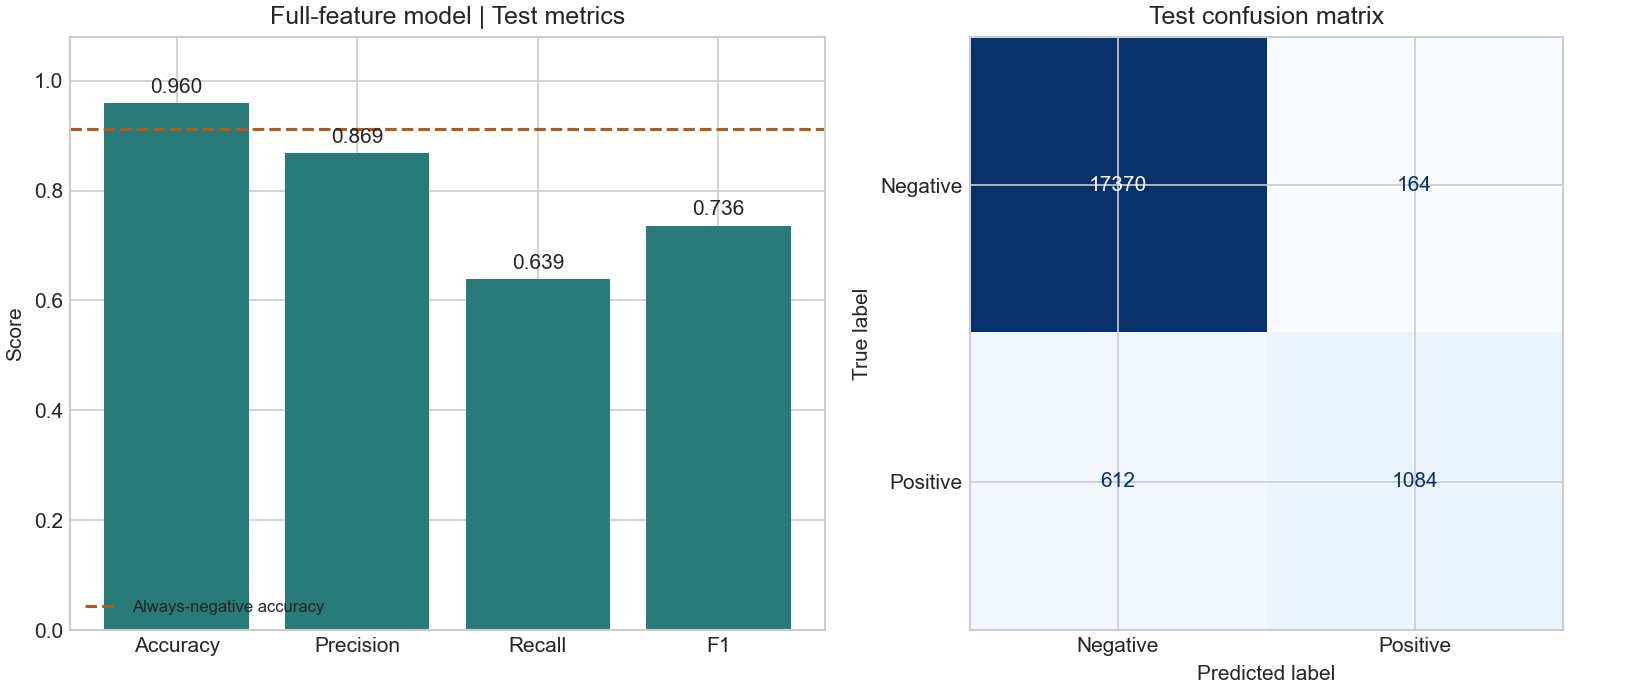

In [4]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# Step 1. Make test predictions at the classifier's default 0.5 threshold.
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
baseline_acc = accuracy_score(y_test, np.zeros_like(y_test))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"Accuracy {acc:.4f}; precision {prec:.4f}; recall {rec:.4f}; F1 {f1:.4f}")
print(f"Always-negative baseline accuracy: {baseline_acc:.4f}")
print(f"True negatives {tn:,}; false positives {fp:,}; false negatives {fn:,}; true positives {tp:,}")

# Step 2. Plot the scores and the confusion matrix with explicit class labels.
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
bars = axes[0].bar(["Accuracy", "Precision", "Recall", "F1"],
                   [acc, prec, rec, f1], color="#287b78")
axes[0].bar_label(bars, fmt="%.3f", padding=3)
axes[0].axhline(baseline_acc, color="#a85f21", linestyle="--",
                label="Always-negative accuracy")
axes[0].set(title="Full-feature model | Test metrics", ylabel="Score", ylim=(0, 1.08))
axes[0].legend(fontsize=8, loc="lower left")
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(
    ax=axes[1], colorbar=False, cmap="Blues"
)
axes[1].set_title("Test confusion matrix")
fig.savefig("evaluation_metrics.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# Step 3. Interpret the imbalance and errors using the computed results.
print(f"The model improves on baseline accuracy by {100 * (acc - baseline_acc):.2f} percentage points.")
print(f"Of positive predictions, {prec:.1%} match positive labels.")
print(f"The model detects {rec:.1%} of positive labels and misses {fn:,}.")
print("Changing the threshold trades precision against recall.")
print("Choose thresholds on validation data using the intended error costs, then evaluate on fresh test data.")

# Exercise 5 | Visualize a two-feature decision boundary

Fit a separate illustrative model using the two features suggested by the template, HbA1c and blood glucose. Keep the same train/test rows. Its accuracy belongs to this two-feature model. The full-feature model above uses all predictors. Lightly jitter the displayed points to reveal overlapping measurements, while predictions and accuracy use the original values.

Two-feature test accuracy: 0.9556; full-feature accuracy: 0.9596


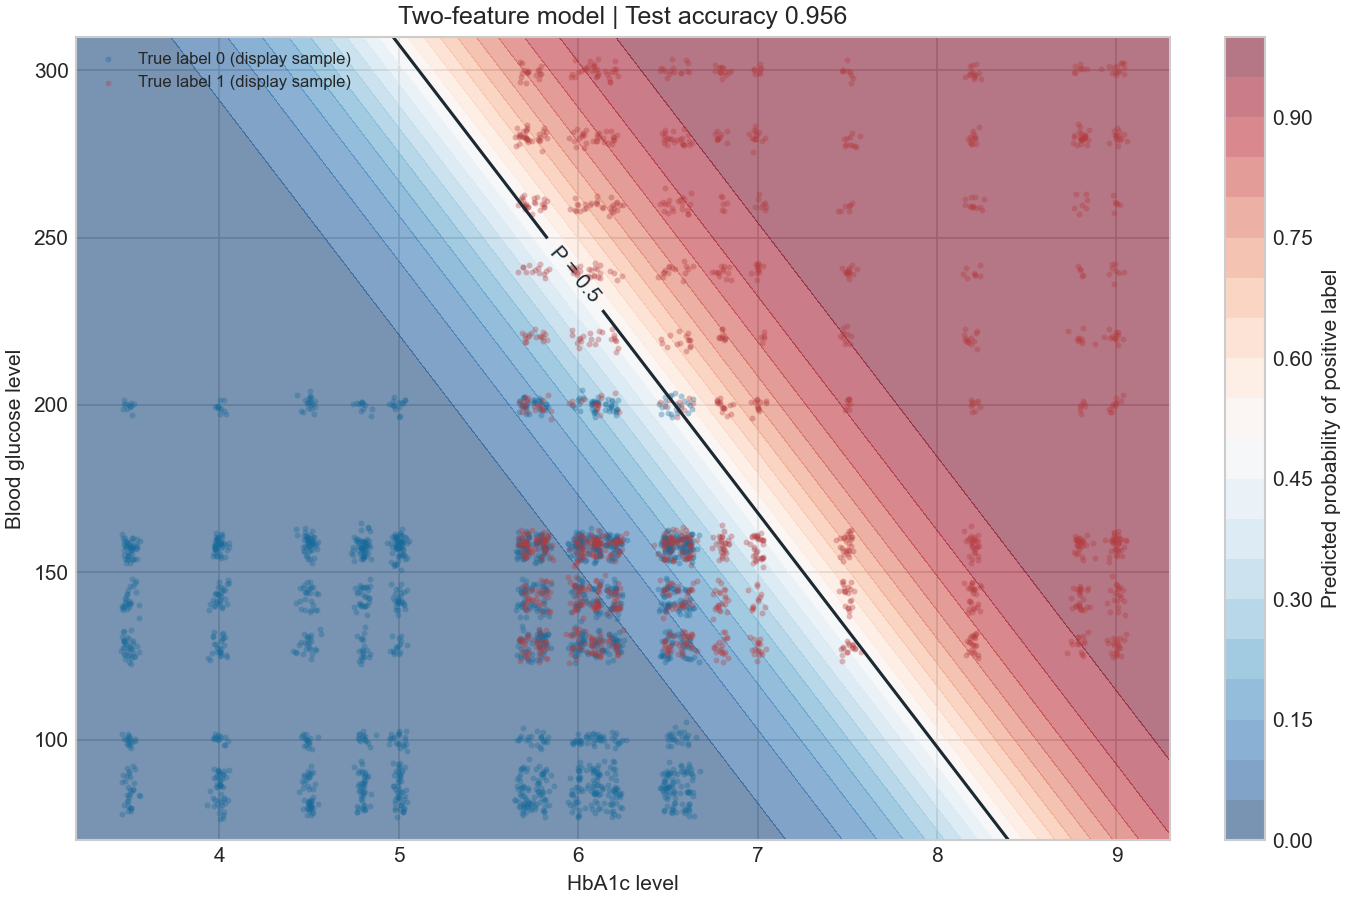

In [5]:
# Step 1. Train a fresh two-feature pipeline with training-only scaling.
plot_features = ["HbA1c_level", "blood_glucose_level"]
X2_train = X_train[plot_features]
X2_test = X_test[plot_features]
pipe2 = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42)),
])
pipe2.fit(X2_train, y_train)
acc2 = accuracy_score(y_test, pipe2.predict(X2_test))

# Step 2. Predict a probability on each location of a two-dimensional grid.
x_values = np.linspace(X2_train.iloc[:, 0].min() - 0.3,
                       X2_train.iloc[:, 0].max() + 0.3, 240)
y_values = np.linspace(X2_train.iloc[:, 1].min() - 10,
                       X2_train.iloc[:, 1].max() + 10, 240)
xx, yy = np.meshgrid(x_values, y_values)
grid = pd.DataFrame(np.column_stack([xx.ravel(), yy.ravel()]), columns=plot_features)
probabilities = pipe2.predict_proba(grid)[:, 1].reshape(xx.shape)

# Step 3. Draw probability shading and the 0.5 classification boundary.
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
surface = ax.contourf(xx, yy, probabilities, levels=np.linspace(0, 1, 21),
                      cmap="RdBu_r", alpha=0.55)
boundary = ax.contour(xx, yy, probabilities, levels=[0.5], colors="#1a2932")
ax.clabel(boundary, fmt={0.5: "P = 0.5"}, inline=True)
rng = np.random.default_rng(42)
for label, color in [(0, "#176a9b"), (1, "#b43b3e")]:
    subset = X2_test.loc[y_test.eq(label)]
    # Display a reproducible sample to limit overplotting in the majority class.
    subset = subset.sample(n=min(2200, len(subset)), random_state=42)
    ax.scatter(subset.iloc[:, 0] + rng.normal(0, 0.025, len(subset)),
                subset.iloc[:, 1] + rng.normal(0, 1.5, len(subset)),
                s=8, alpha=0.35, linewidths=0, color=color,
                label=f"True label {label} (display sample)")
ax.set(title=f"Two-feature model | Test accuracy {acc2:.3f}",
       xlabel="HbA1c level", ylabel="Blood glucose level")
ax.legend(fontsize=8, loc="upper left")
fig.colorbar(surface, ax=ax, label="Predicted probability of positive label")
fig.savefig("decision_boundary.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)
print(f"Two-feature test accuracy: {acc2:.4f}; full-feature accuracy: {acc:.4f}")

# Exercise 6 | ROC curve and AUC

Use continuous predicted probabilities from the fitted full-feature model. ROC plots true-positive rate (recall) against false-positive rate across thresholds. The diagonal is the random-ranking reference. AUC summarizes ranking discrimination and can be interpreted as the probability that a randomly selected positive receives a higher score than a randomly selected negative, with half credit for ties.

ROC AUC: 0.9598
At threshold 0.5, TPR = 0.6392 and FPR = 0.0094.
AUC evaluates ranking across thresholds. Probability calibration needs a separate check.
Validation on independent, representative data would be needed to assess generalization.
# Diabetes Classification | Completed Exercises XP

The notebook follows the six exercises in the supplied Colab template.
All preprocessing is fitted on training data. Positive metrics refer to label 1.

- Source records: 100,000, with 8,500 positives and 91,500 negatives.
- Exact duplicate rows removed before splitting: 3,854.
- Cleaned records: 96,146, with 8,482 positives and 87,664 negatives.
- Stratified 80/20 split: 76,916 training and 19,230 test rows.
- Accuracy: 95.96%, versus always-negative baseline 91.18%.
- Positive-class precision: 86.86%; recall: 63.92%; F1: 0.7364.
- Confusion counts: TN 17,370, FP 164, FN 612, TP 1,084.
- ROC AUC: 0.9598.
- Separate two-feature decision-boundary model accuracy: 95.56%.

This exercise classifies t

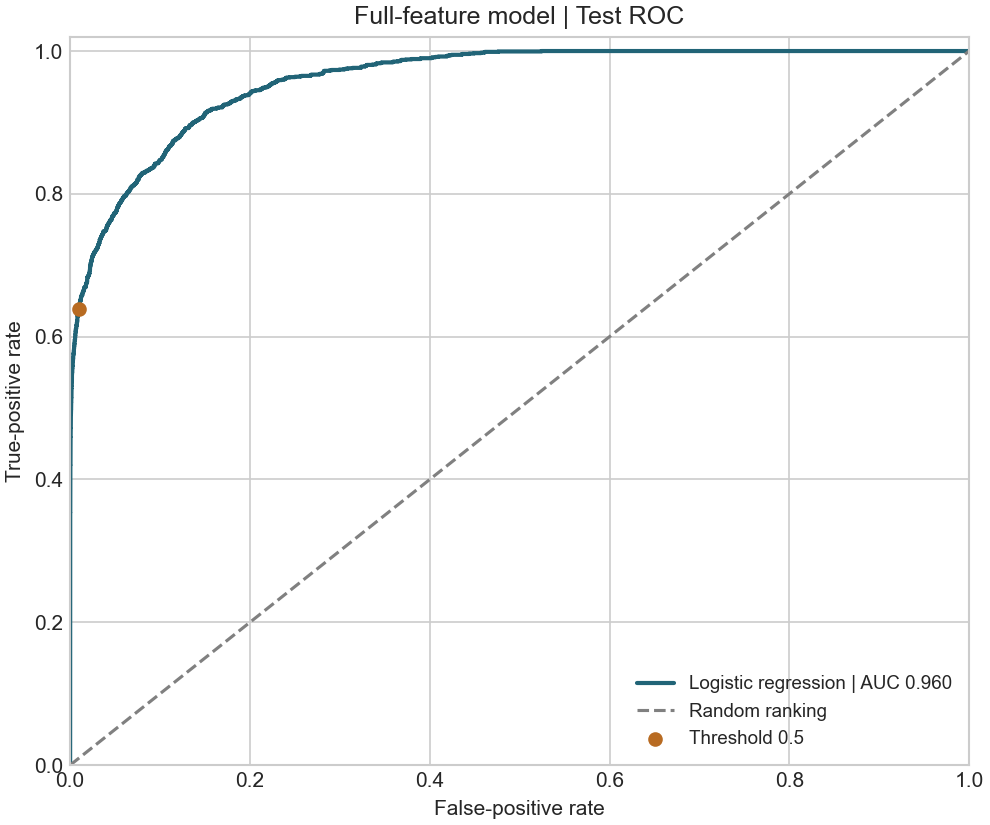

In [6]:
from sklearn import metrics

# Step 1. Get positive-class probabilities and calculate the ROC curve and AUC.
y_proba = clf.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_proba)
auc = metrics.roc_auc_score(y_test, y_proba)

# Step 2. Plot the curve and the default-threshold operating point.
fig, ax = plt.subplots(figsize=(6.6, 5.5), layout="constrained")
ax.plot(fpr, tpr, color="#216477", lw=2, label=f"Logistic regression | AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.scatter(fp / (fp + tn), rec, color="#b86b22", zorder=3, label="Threshold 0.5")
ax.set(title="Full-feature model | Test ROC", xlabel="False-positive rate",
       ylabel="True-positive rate", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right", fontsize=9)
fig.savefig("roc_curve.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)
print(f"ROC AUC: {auc:.4f}")
print(f"At threshold 0.5, TPR = {rec:.4f} and FPR = {fp / (fp + tn):.4f}.")
print("AUC evaluates ranking across thresholds. Probability calibration needs a separate check.")
print("Validation on independent, representative data would be needed to assess generalization.")

# Step 3. Write the numerical answers into a compact summary beside the notebook.
report = f"""# Diabetes Classification | Completed Exercises XP

The notebook follows the six exercises in the supplied Colab template.
All preprocessing is fitted on training data. Positive metrics refer to label 1.

- Source records: {len(raw):,}, with {raw.diabetes.eq(1).sum():,} positives and {raw.diabetes.eq(0).sum():,} negatives.
- Exact duplicate rows removed before splitting: {len(raw) - len(df):,}.
- Cleaned records: {len(df):,}, with {df.diabetes.eq(1).sum():,} positives and {df.diabetes.eq(0).sum():,} negatives.
- Stratified 80/20 split: {len(X_train):,} training and {len(X_test):,} test rows.
- Accuracy: {acc:.2%}, versus always-negative baseline {baseline_acc:.2%}.
- Positive-class precision: {prec:.2%}; recall: {rec:.2%}; F1: {f1:.4f}.
- Confusion counts: TN {tn:,}, FP {fp:,}, FN {fn:,}, TP {tp:,}.
- ROC AUC: {auc:.4f}.
- Separate two-feature decision-boundary model accuracy: {acc2:.2%}.

This exercise classifies the recorded diabetes label. Future onset has no
defined follow-up window in these data. The probability estimates and intended
use would need further assessment.

Open diabetes_classification.ipynb in Jupyter or upload it to Colab. Keep
diabetes_prediction_dataset.zip beside it. Install numpy, pandas, scikit-learn
and matplotlib before running locally. The course asks you to share the
completed Colab link publicly and paste it into DI Learning after review.
"""
Path("RESULTS.md").write_text(report, encoding="utf-8")
print(report)